In [3]:
# create animation from png
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import os

In [4]:
thk = 1.5


if thk == 0.0:

    root_base = f'/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/simulation_no_sediment_on_top_JAP/RESULTS'

else:
    root_base = f'/mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/simulation_sediment_on_top_{thk}m_JAP/RESULTS'

fname_wh = 'OUTPUT_FILES_2026-10-06_13-30-33_wh'
fname_tr = 'OUTPUT_FILES_2026-10-06_13-50-46_tr'

rooth_path_wh = f'{root_base}/{fname_wh}'
jpg_files_wh = sorted([f for f in os.listdir(rooth_path_wh) if f.lower().endswith(('.jpg', '.jpeg'))])
    
rooth_path_tr = f'{root_base}/{fname_tr}'
jpg_files_tr = sorted([f for f in os.listdir(rooth_path_tr) if f.lower().endswith(('.jpg', '.jpeg'))])

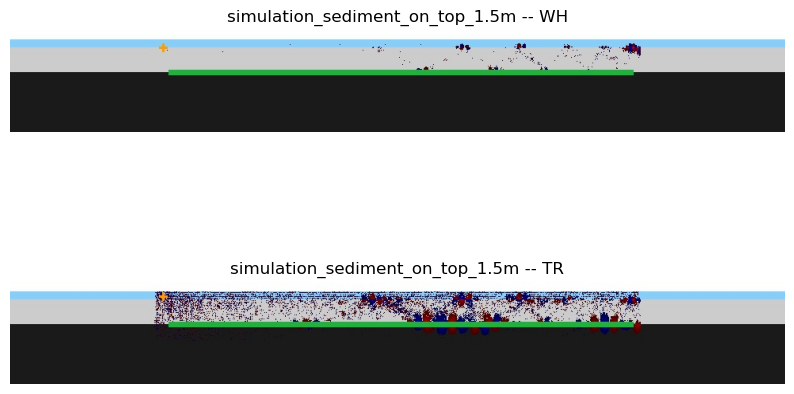

Saved 131 frames to /mnt/p/11212604-jip-sense/DAS/SPECFEM2D_OUTPUTS/JAPANESE_SOIL_CONDITIONS/simulation_sediment_on_top_1.5m_JAP/RESULTS/animation_wh_vs_tr.gif


In [5]:
if not jpg_files_wh:
    raise FileNotFoundError(f"No JPG frames found in {rooth_path_wh}")

if not jpg_files_tr:
    raise FileNotFoundError(f"No JPG frames found in {rooth_path_tr}")

# use only half of the figure height for each subplot

fig, (ax0,ax1) = plt.subplots(2,1,figsize=(10, 6))

img0 = jpg_files_wh[0]
# crop image to use only half of the figure height
img0_path = os.path.join(rooth_path_wh, img0)
img0_data = plt.imread(img0_path)
img0_data = img0_data[:img0_data.shape[0]//2, :]
img0 = ax0.imshow(img0_data)
ax0.axis("off")
# add titles for the subplots
ax0.set_title(f"simulation_sediment_on_top_{thk}m -- WH")
ax1.set_title(f"simulation_sediment_on_top_{thk}m -- TR")
img1 = jpg_files_tr[0]
# crop image to use only half of the figure height
img1_path = os.path.join(rooth_path_tr, img1)
img1_data = plt.imread(img1_path)
img1_data = img1_data[:img1_data.shape[0]//2, :]
img1 = ax1.imshow(img1_data)
ax1.axis("off")

def update(frame):
    img0_path = os.path.join(rooth_path_wh, jpg_files_wh[frame])
    img0_data = plt.imread(img0_path)
    img0_data = img0_data[:img0_data.shape[0]//2, :]
    img0.set_data(img0_data)
    img1_path = os.path.join(rooth_path_tr, jpg_files_tr[frame])
    img1_data = plt.imread(img1_path)
    img1_data = img1_data[:img1_data.shape[0]//2, :]
    img1.set_data(img1_data)    
    return (img0, img1)

ani = animation.FuncAnimation(fig, update, frames=min(len(jpg_files_wh), len(jpg_files_tr)), blit=True)
output_path = os.path.join(root_base, "animation_wh_vs_tr.gif")
ani.save(output_path, writer=animation.PillowWriter(fps=4))
plt.show()
print(f"Saved {min(len(jpg_files_wh), len(jpg_files_tr))} frames to {output_path}")